# Bước 4 & Bước 5: Thêm Mô hình GAT vào Cùng Quy trình & Chạy Thực nghiệm Nhiều Seed

**Mục tiêu của Notebook này:**
1. **Bước 4 (GAT):** Thay `GCNEncoder` bằng `GATEncoder` (với `heads=4`, lớp 1 `concat=True` chiều `16×4=64`, lớp 2 `concat=False` chiều `64` khớp với `LinkDecoder`). Giữ nguyên toàn bộ dữ liệu, các tập chia, `LinkDecoder`, `BCEWithLogitsLoss`, cách chọn checkpoint theo `Validation AP` và chọn ngưỡng `F1`.
2. **Bước 5 (Thực nghiệm chính thức):**
   - Chạy thực nghiệm với **3 seeds** (`42, 43, 44`) cho cả **GCN** và **GAT**.
   - Đánh giá trên kịch bản tổng thể (`Overall`) và 5 kịch bản phân lớp mẫu âm (`Scenario 1..5`).
   - Tổng hợp giá trị trung bình và độ lệch chuẩn (`Mean ± Std`), xuất bảng kết quả chuẩn:
     `Scenario | Model | Seed | ROC-AUC | AP | F1 | Hits@10`
   - Lưu toàn bộ cấu hình, checkpoint, ngưỡng F1, điểm dự đoán và biểu đồ Loss / Validation AP vào `outputs/`.

## 4.1. Nạp Dữ liệu & Kiểm tra Cùng Một Hàm Chạy cho cả `GCN` và `GAT`

In [1]:
import json
import os
import sys
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.data_validator import build_homogeneous_customer_graph, load_split_pairs
from src.models import GNNLinkPredictor, train_and_evaluate_model
from src.metrics import evaluate_all, evaluate_by_negative_types
from src.viz_utils import plot_training_curves, plot_scenario_comparison

graph_dict = build_homogeneous_customer_graph()
splits = load_split_pairs()
x = graph_dict["x"]
edge_index = graph_dict["edge_index"]

for m_type in ["GCN", "GAT"]:
    tmp_model = GNNLinkPredictor(model_type=m_type, in_channels=x.shape[1], hidden_channels=64, out_channels=64, heads=4)
    n_params = sum(p.numel() for p in tmp_model.parameters() if p.requires_grad)
    print(f"Model {m_type:3s} | Config: {tmp_model.config} | Trainable params: {n_params:,}")

Model GCN | Config: {'model_type': 'GCN', 'in_channels': 60, 'hidden_channels': 64, 'out_channels': 64, 'heads': 1, 'dropout': 0.2} | Trainable params: 26,881
Model GAT | Config: {'model_type': 'GAT', 'in_channels': 60, 'hidden_channels': 64, 'out_channels': 64, 'heads': 4, 'dropout': 0.2} | Trainable params: 39,809


## 5.1. Chạy Thực nghiệm Chính thức trên 3 Seeds (`[42, 43, 44]`) cho GCN và GAT

In [2]:
SEEDS = [42, 43, 44]
MODELS = ["GCN", "GAT"]
EPOCHS = 60

all_seed_rows = []
saved_metadata = {}
histories_seed42 = {}

for model_name in MODELS:
    for seed in SEEDS:
        ckpt_file = os.path.join(PROJECT_ROOT, "outputs", "checkpoints", f"{model_name.lower()}_seed{seed}.pt")
        pred_file = os.path.join(PROJECT_ROOT, "outputs", "predictions", f"{model_name.lower()}_seed{seed}_predictions.pt")

        run_res = train_and_evaluate_model(
            model_type=model_name,
            x=x,
            edge_index=edge_index,
            splits=splits,
            seed=seed,
            epochs=EPOCHS,
            lr=3e-3,
            hidden_channels=64,
            out_channels=64,
            heads=4,
            dropout=0.2,
            checkpoint_path=ckpt_file,
            verbose=True,
        )

        if seed == 42:
            histories_seed42[model_name] = run_res["history"]

        sc_df = evaluate_by_negative_types(
            val_y_true=run_res["val_y_true"],
            val_y_score=run_res["val_y_score"],
            test_y_true=run_res["test_y_true"],
            test_y_score=run_res["test_y_score"],
            test_edge_type=splits["test"]["edge_type"],
            model_name=model_name,
            seed=seed,
            k=10,
        )
        all_seed_rows.append(sc_df)

        best_th = float(sc_df["Threshold"].iloc[0])
        os.makedirs(os.path.dirname(pred_file), exist_ok=True)
        torch.save(
            {
                "model": model_name,
                "seed": seed,
                "threshold": best_th,
                "val_y_true": torch.from_numpy(run_res["val_y_true"]),
                "val_y_score": torch.from_numpy(run_res["val_y_score"]),
                "test_y_true": torch.from_numpy(run_res["test_y_true"]),
                "test_y_score": torch.from_numpy(run_res["test_y_score"]),
                "test_edge_type": splits["test"]["edge_type"].cpu(),
                "test_edge_label_index": splits["test"]["edge_label_index"].cpu(),
            },
            pred_file,
        )

        saved_metadata[f"{model_name}_seed{seed}"] = {
            "config": run_res["config"],
            "seed": seed,
            "best_epoch": run_res["best_epoch"],
            "best_val_ap": round(run_res["best_val_ap"], 4),
            "f1_threshold": round(best_th, 4),
            "checkpoint_path": f"outputs/checkpoints/{model_name.lower()}_seed{seed}.pt",
            "prediction_path": f"outputs/predictions/{model_name.lower()}_seed{seed}_predictions.pt",
        }

meta_path = os.path.join(PROJECT_ROOT, "outputs", "checkpoints", "experiment_configs_and_thresholds.json")
with open(meta_path, "w", encoding="utf-8") as f:
    json.dump(saved_metadata, f, indent=2, ensure_ascii=False)

results_per_seed_df = pd.concat(all_seed_rows, ignore_index=True)
per_seed_csv = os.path.join(PROJECT_ROOT, "outputs", "tables", "results_per_seed.csv")
os.makedirs(os.path.dirname(per_seed_csv), exist_ok=True)
results_per_seed_df.to_csv(per_seed_csv, index=False)

print("\n=== BẢNG KẾT QUẢ CHI TIẾT TỪNG SEED (Scenario | Model | Seed | ROC-AUC | AP | F1 | Hits@10) ===")
display(results_per_seed_df[["Scenario", "Model", "Seed", "ROC-AUC", "AP", "F1", "Hits@10", "Threshold"]])

[GCN | Seed 42] Epoch 001/060 | Train Loss: 0.6975 | Val Loss: 0.6472 | Val AP: 0.7637 (Best: 0.7637 @ Ep 1)
[GCN | Seed 42] Epoch 020/060 | Train Loss: 0.4822 | Val Loss: 0.5082 | Val AP: 0.7852 (Best: 0.7852 @ Ep 20)
[GCN | Seed 42] Epoch 040/060 | Train Loss: 0.3878 | Val Loss: 0.5069 | Val AP: 0.8412 (Best: 0.8412 @ Ep 39)
[GCN | Seed 42] Epoch 060/060 | Train Loss: 0.2999 | Val Loss: 0.6014 | Val AP: 0.8437 (Best: 0.8510 @ Ep 50)
[GCN | Seed 43] Epoch 001/060 | Train Loss: 0.7046 | Val Loss: 0.6563 | Val AP: 0.7432 (Best: 0.7432 @ Ep 1)
[GCN | Seed 43] Epoch 020/060 | Train Loss: 0.4791 | Val Loss: 0.5032 | Val AP: 0.8072 (Best: 0.8072 @ Ep 20)
[GCN | Seed 43] Epoch 040/060 | Train Loss: 0.3940 | Val Loss: 0.5059 | Val AP: 0.8419 (Best: 0.8470 @ Ep 39)
[GCN | Seed 43] Epoch 060/060 | Train Loss: 0.2994 | Val Loss: 0.5996 | Val AP: 0.8442 (Best: 0.8509 @ Ep 41)
[GCN | Seed 44] Epoch 001/060 | Train Loss: 0.6890 | Val Loss: 0.6434 | Val AP: 0.7533 (Best: 0.7533 @ Ep 1)
[GCN | Seed 4

Scenario,Model,Seed,ROC-AUC,AP,F1,Hits@10,Threshold
Overall (All 5 Neg Types),GCN,42,0.8152,0.8060,0.7586,0.6813,0.3227
Scenario 1: AML-AML (Cross-Case),GCN,42,0.5999,0.8427,0.7849,0.3497,0.3227
Scenario 2: AML-Clean,GCN,42,0.8524,0.9769,0.8619,0.7556,0.3227
Scenario 3: Suspected KYC,GCN,42,0.9206,0.9874,0.8773,0.8579,0.3227
Scenario 4: Shared IP/Device,GCN,42,0.8374,0.9944,0.8793,0.9175,0.3227
Scenario 5: Clean-Clean Random,GCN,42,0.9274,0.9749,0.8742,0.8807,0.3227
Overall (All 5 Neg Types),GCN,43,0.8056,0.7901,0.7515,0.6649,0.3955
Scenario 1: AML-AML (Cross-Case),GCN,43,0.5958,0.8331,0.7937,0.3263,0.3955
Scenario 2: AML-Clean,GCN,43,0.8451,0.9757,0.8630,0.7380,0.3955
Scenario 3: Suspected KYC,GCN,43,0.9204,0.9880,0.8822,0.8509,0.3955


## 5.2. Tổng hợp Trung bình & Độ lệch chuẩn (`Mean ± Std`) qua 3 Seeds

In [3]:
metrics_cols = ["ROC-AUC", "AP", "F1", "Hits@10"]
grouped = results_per_seed_df.groupby(["Scenario", "Model"], sort=False)[metrics_cols].agg(["mean", "std"]).reset_index()
grouped.columns = [
    f"{a}_{b}" if b else a for a, b in grouped.columns.to_flat_index()
]

formatted_rows = []
for _, row in grouped.iterrows():
    item = {"Scenario": row["Scenario"], "Model": row["Model"]}
    for m in metrics_cols:
        item[m] = f"{row[f'{m}_mean']:.4f} ± {row[f'{m}_std']:.4f}"
    formatted_rows.append(item)

formatted_summary_df = pd.DataFrame(formatted_rows)
mean_std_csv = os.path.join(PROJECT_ROOT, "outputs", "tables", "results_mean_std.csv")
grouped.to_csv(mean_std_csv, index=False)
formatted_csv = os.path.join(PROJECT_ROOT, "outputs", "tables", "results_mean_std_formatted.csv")
formatted_summary_df.to_csv(formatted_csv, index=False)

print("=== BẢNG TỔNG HỢP KẾT QUẢ CHÍNH THỨC (MEAN ± STD TRÊN 3 SEEDS) ===")
display(formatted_summary_df)

=== BẢNG TỔNG HỢP KẾT QUẢ CHÍNH THỨC (MEAN ± STD TRÊN 3 SEEDS) ===


Scenario,Model,ROC-AUC,AP,F1,Hits@10
Overall (All 5 Neg Types),GCN,0.8113 ± 0.0050,0.7976 ± 0.0080,0.7558 ± 0.0038,0.6704 ± 0.0095
Scenario 1: AML-AML (Cross-Case),GCN,0.6020 ± 0.0075,0.8386 ± 0.0049,0.7896 ± 0.0044,0.3396 ± 0.0120
Scenario 2: AML-Clean,GCN,0.8493 ± 0.0038,0.9761 ± 0.0007,0.8628 ± 0.0008,0.7526 ± 0.0134
Scenario 3: Suspected KYC,GCN,0.9206 ± 0.0002,0.9875 ± 0.0004,0.8790 ± 0.0027,0.8575 ± 0.0064
Scenario 4: Shared IP/Device,GCN,0.8306 ± 0.0064,0.9930 ± 0.0013,0.8823 ± 0.0043,0.9045 ± 0.0129
Scenario 5: Clean-Clean Random,GCN,0.9170 ± 0.0095,0.9709 ± 0.0035,0.8708 ± 0.0036,0.8571 ± 0.0206
Overall (All 5 Neg Types),GAT,0.8000 ± 0.0005,0.7918 ± 0.0049,0.7383 ± 0.0043,0.6477 ± 0.0039
Scenario 1: AML-AML (Cross-Case),GAT,0.5934 ± 0.0079,0.8367 ± 0.0070,0.7690 ± 0.0058,0.3462 ± 0.0176
Scenario 2: AML-Clean,GAT,0.8314 ± 0.0149,0.9731 ± 0.0027,0.8382 ± 0.0076,0.7189 ± 0.0105
Scenario 3: Suspected KYC,GAT,0.9152 ± 0.0035,0.9869 ± 0.0010,0.8544 ± 0.0050,0.8536 ± 0.0131


## 5.3. Vẽ Biểu đồ Loss / Validation AP & Biểu đồ So sánh GCN vs GAT

Đã lưu biểu đồ tại: C:\KOUPC\study\5th\DSS\CK\outputs\figures\training_curves_loss_val_ap.png và C:\KOUPC\study\5th\DSS\CK\outputs\figures\scenario_comparison_bar.png


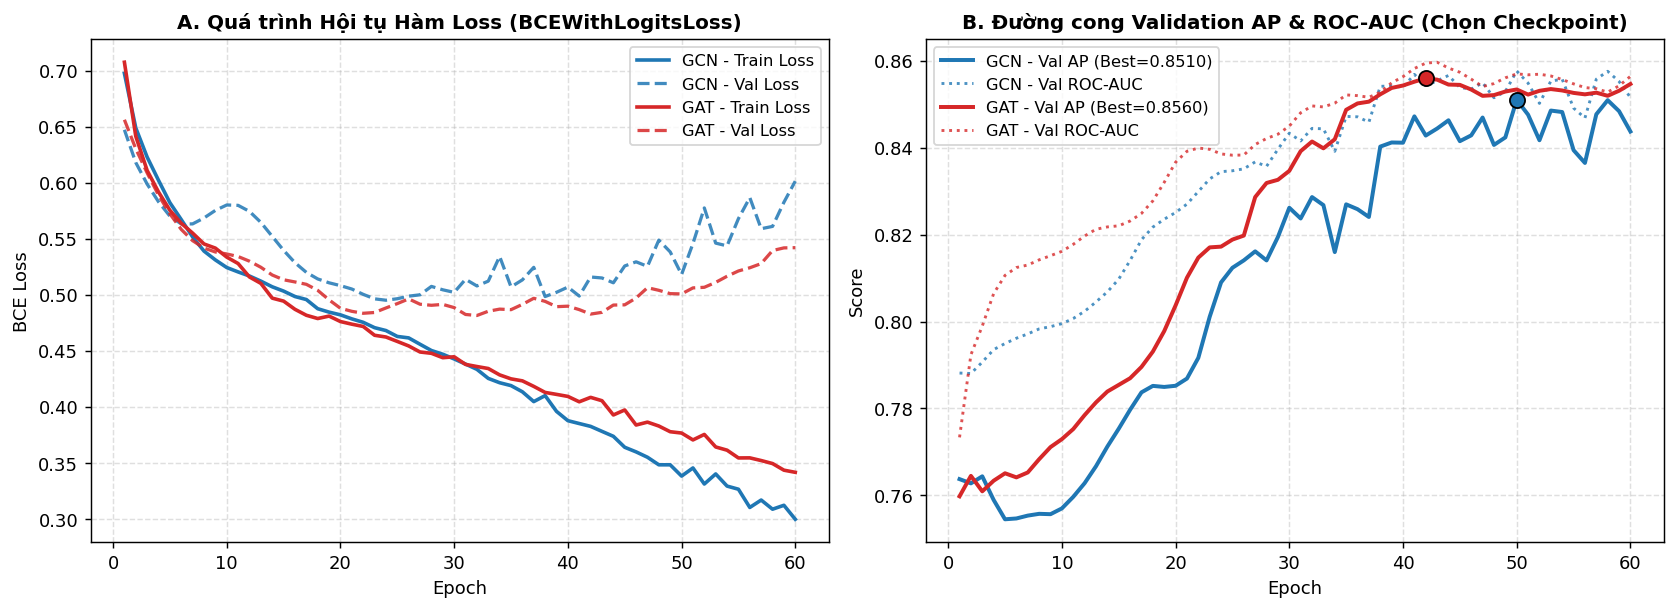

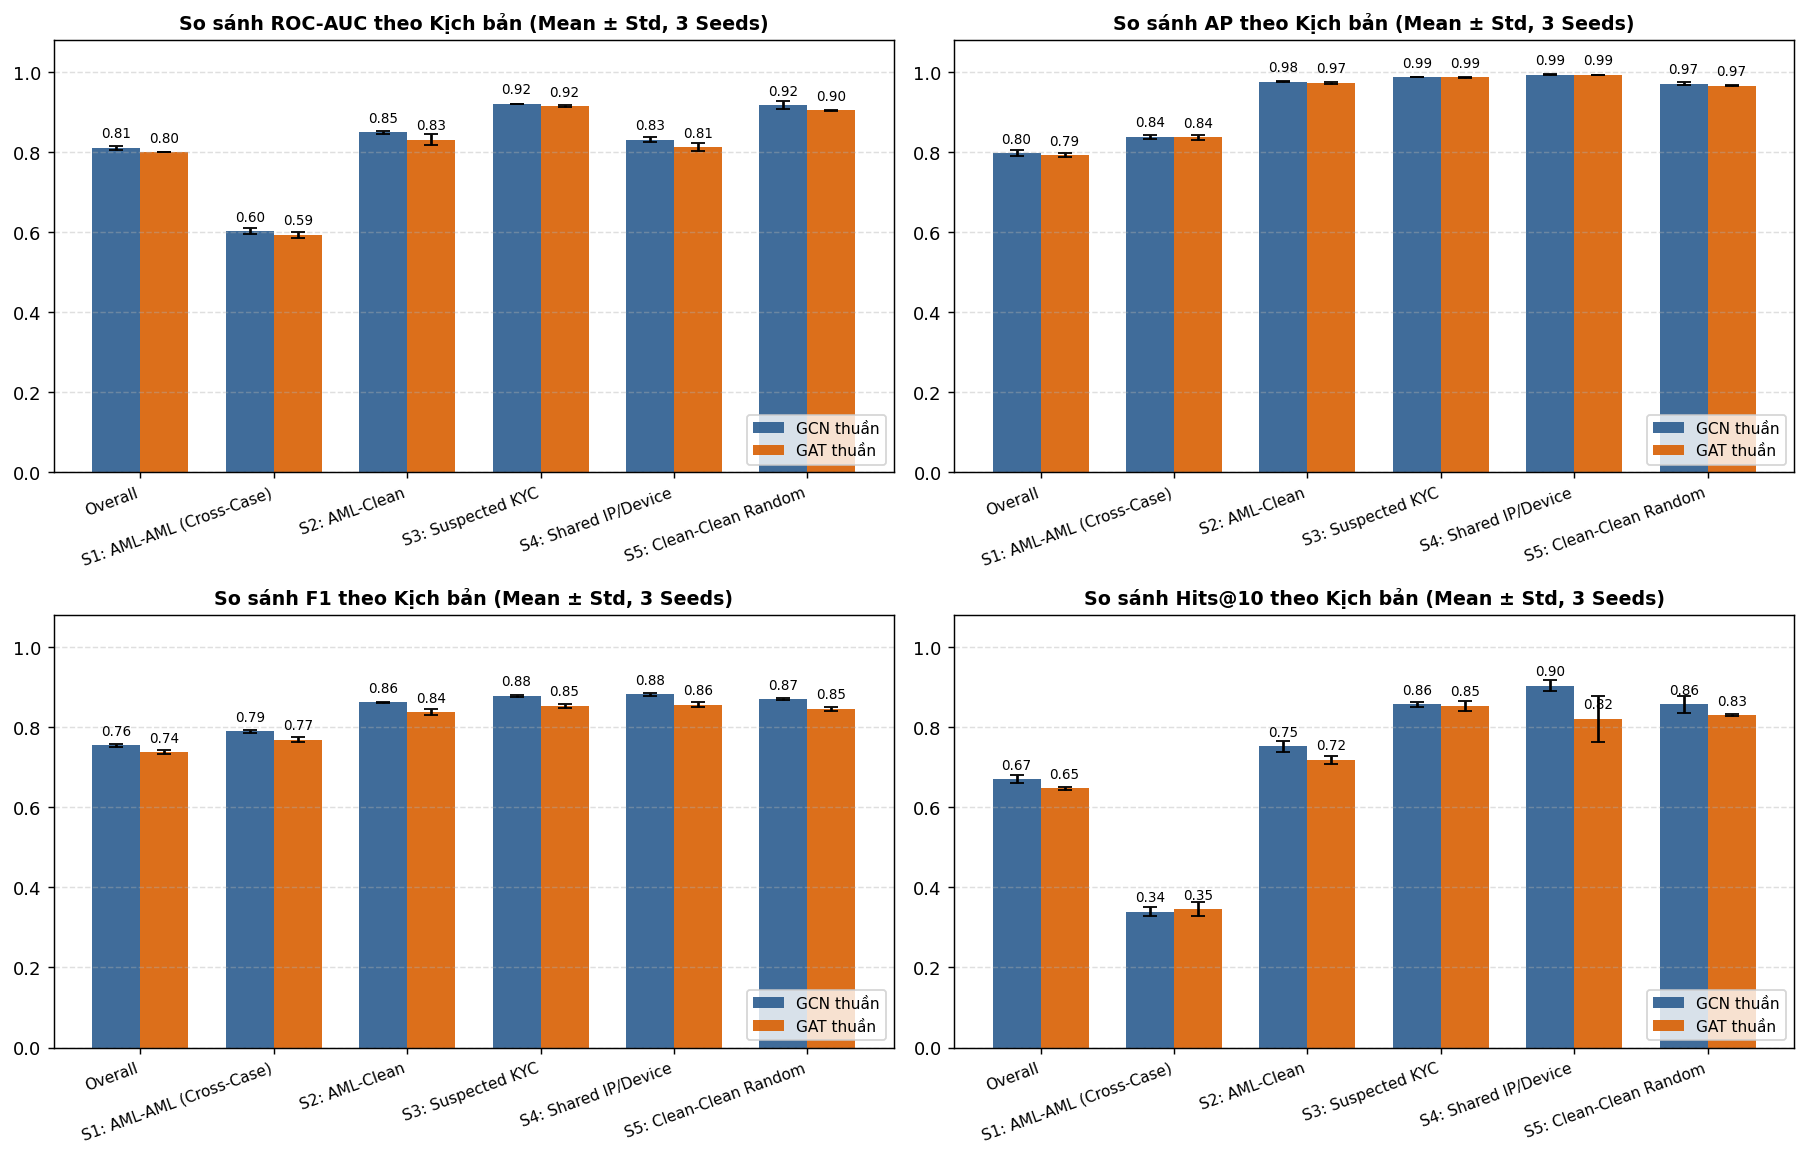

In [4]:
curve_fig_path = os.path.join(PROJECT_ROOT, "outputs", "figures", "training_curves_loss_val_ap.png")
fig1 = plot_training_curves(histories_seed42, save_path=curve_fig_path)
plt.show()

bar_fig_path = os.path.join(PROJECT_ROOT, "outputs", "figures", "scenario_comparison_bar.png")
fig2 = plot_scenario_comparison(grouped, save_path=bar_fig_path)
plt.show()

print("Đã lưu biểu đồ tại:", curve_fig_path, "và", bar_fig_path)